# Super Mario Bros (DQN y DDQN)

In [1]:
import gym_super_mario_bros
from gym_super_mario_bros.actions import RIGHT_ONLY
from nes_py.wrappers import JoypadSpace
from IPython.display import clear_output, display
from PIL import Image
from gym import Wrapper
from gym.wrappers import GrayScaleObservation, ResizeObservation, FrameStack
import gym.wrappers
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from tensordict import TensorDict
from torchrl.data import TensorDictReplayBuffer, LazyMemmapStorage
import torch.nn.functional as F
import os
import time
import datetime
from tqdm import tqdm

%matplotlib inline

## Veamos como es el ambiente de SMB usando unicamente acciones hacia la derecha

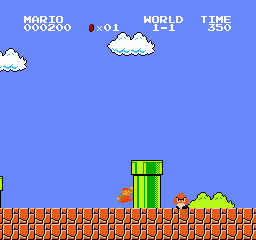

In [2]:
env_name = 'SuperMarioBros-1-1-v0'

env = gym_super_mario_bros.make(env_name, render_mode='rgb_array', apply_api_compatibility=True)
env = JoypadSpace(env, RIGHT_ONLY)
done = False
state, _ = env.reset()

for _  in range(1000):
    action = env.action_space.sample() # Muestrea una accion aleatoria
    state, reward, done, truncated, info  = env.step(action)
    # Tomar una imagen del ambiente para visualizar
    img = env.render()

    # Mostrar la imagen con IPython
    clear_output(wait=True)
    display(Image.fromarray(np.array(img), 'RGB'))
    if done:
        break
env.close()

## Crear las clases para el pre-procesamiento de los frames

In [11]:
class SkipFrame(Wrapper):
    def __init__(self, env, skip):
        super().__init__(env)
        self.skip = skip
    
    def step(self, action):
        total_reward = 0.0
        done = False
        for _ in range(self.skip):
            next_state, reward, done, trunc, info = self.env.step(action)
            total_reward += reward
            if done:
                break
        return next_state, total_reward, done, trunc, info
    

def apply_wrappers(env):
    env = SkipFrame(env, skip=4) # Numero de frames a las que se le aplicara una accion
    env = ResizeObservation(env, shape=84) # Cambiar el tamano del frame de 240x256 a 84x84
    env = GrayScaleObservation(env)
    env = FrameStack(env, num_stack=4, lz4_compress=True) # Cambiar lz4_compress a False si hay problemas
    return env

## Crear una CNN para entrenar el modelo DQN

In [12]:
class MarioNet(nn.Module):
    '''Mario Network'''
    def __init__(self, state_dim, action_dim, freeze = False):
        super(MarioNet, self).__init__()
        
        # Capas convolucionales
        self.conv1 = nn.Conv2d(state_dim[0], 32, kernel_size=8, stride=4)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2)
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1)

        # Cálculo del tamaño de salida de la última capa conv
        dummy_input = torch.zeros(1, *state_dim).detach()
        conv_out = self._get_conv_out(dummy_input)
        
        # Capas completamente conectadas
        self.fc1 = nn.Linear(conv_out, 512)
        self.fc2 = nn.Linear(512, action_dim)

        if freeze:
            self._freeze()
            
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.to(self.device)

    def _get_conv_out(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        return int(np.prod(x.size()))

    def _freeze(self):
        for p in self.parameters():
            p.requires_grad = False

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = x.view(x.size(0), -1)  # flatten
        x = F.relu(self.fc1(x))
        return self.fc2(x)


In [13]:
class Mario:
    def __init__(self, state_dim, action_dim, lr=0.00025, gamma=0.9, epsilon=1.0, 
                 epsilon_min=0.1, epsilon_decay=0.99999975, capacity=10_000, 
                 batch_size=32, target_update = 10_000, dqn_type = 'DQN'):
        
        # Hyperparameters
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.batch_size = batch_size
        self.target_update = target_update
        self.action_dim = action_dim
        self.dqn_type = dqn_type
        self.count = 0

        # Q-Networks
        self.q_net = MarioNet(state_dim, action_dim)
        self.target_q_net = MarioNet(state_dim, action_dim, freeze=True)

        # Optimizer and loss
        self.optimizer = torch.optim.Adam(self.q_net.parameters(), lr=self.lr)
        self.loss = torch.nn.MSELoss()

        # Buffer de experiencias
        storage = LazyMemmapStorage(capacity)
        self.replay_buffer = TensorDictReplayBuffer(storage=storage)

    def take_action(self, observation):  # Estrategia epsilon-greedy para tomar acciones
        if np.random.random() < self.epsilon:
            return np.random.randint(self.action_dim)
        observation = torch.tensor(np.array(observation), dtype=torch.float32) \
                        .unsqueeze(0) \
                        .to(self.q_net.device)
        return self.q_net(observation).argmax().item()
    
    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def store_in_memory(self, state, action, reward, next_state, done):
        self.replay_buffer.add(TensorDict({
                                            "state": torch.tensor(np.array(state), dtype=torch.float32), 
                                            "action": torch.tensor(action),
                                            "reward": torch.tensor(reward), 
                                            "next_state": torch.tensor(np.array(next_state), dtype=torch.float32), 
                                            "done": torch.tensor(done)
                                          }, batch_size=[]))
        
    def sync_networks(self):
        if self.count % self.target_update == 0 and self.count > 0:
            self.target_q_net.load_state_dict(self.q_net.state_dict()) # Acutalizar target network

    def save_model(self, path):
        torch.save(self.q_net.state_dict(), path)

    def load_model(self, path):
        self.q_net.load_state_dict(torch.load(path))
        self.target_q_net.load_state_dict(torch.load(path))

    def update(self):
        if len(self.replay_buffer) < self.batch_size:
            return
        
        self.sync_networks()
        
        self.optimizer.zero_grad()

        samples = self.replay_buffer.sample(self.batch_size).to(self.q_net.device)

        keys = ("state", "action", "reward", "next_state", "done")

        states, actions, rewards, next_states, dones = [samples[key] for key in keys]

        q_values = self.q_net(states) # Shape is (batch_size, n_actions)
        q_values = q_values.gather(1, actions.unsqueeze(1))  # Shape: (batch_size, 1)
        #q_values = q_values[np.arange(self.batch_size), actions.squeeze()]

        if self.dqn_type == 'DDQN':
            max_action = self.q_net(next_states).max(dim = 1)[1].unsqueeze(1)
            max_next_q_values = self.target_q_net(next_states).gather(1, max_action).squeeze(1)
        else:
            max_next_q_values = self.target_q_net(next_states).max(dim=1)[0]

        # Max returns two tensors, the first one is the maximum value, the second one is the index of the maximum value
        q_targets = rewards + self.gamma * max_next_q_values * (1 - dones.float())

        dqn_loss = self.loss(q_values, q_targets.unsqueeze(1))
        dqn_loss.backward()
        self.optimizer.step()

        self.count += 1
        self.decay_epsilon()
 

In [15]:
def get_current_date_time_string():
    return datetime.datetime.now().strftime("%Y-%m-%d-%H_%M_%S")
    
model_path = os.path.join("models", get_current_date_time_string())
os.makedirs(model_path, exist_ok=True)

if torch.cuda.is_available():
    print("Using CUDA device:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available")

env_name = 'SuperMarioBros-1-1-v3'
Mariodisplay = False
ckpt_save_interval = 500
num_episodes = 100
dqn_type = 'DDQN'

env = gym_super_mario_bros.make(env_name, render_mode='human' if Mariodisplay else 'rgb_array', apply_api_compatibility=True)
env = JoypadSpace(env, RIGHT_ONLY)
env = apply_wrappers(env)
agent = Mario(state_dim=env.observation_space.shape, action_dim=env.action_space.n, dqn_type= dqn_type)

return_list = []
    
for i_episode in range(num_episodes):
    episode_return = 0
    done = False
    state, _ = env.reset()
    with tqdm(desc=f'Episodio {i_episode + 1}/{num_episodes}') as pbar:
        while not done:
            action = agent.take_action(state)
            next_state, reward, done, truncated, _ = env.step(action)
            episode_return += reward
            agent.store_in_memory(state, action, reward, next_state, done)
            agent.update()
            state = next_state
        return_list.append(episode_return)
        
        pbar.set_postfix({
            'Retorno':
            '%.3f' % episode_return,
            'Buffer':
            '%d' % (len(agent.replay_buffer)),
            'epsilon':
            '%.3f' % agent.epsilon
        })
        pbar.update(1)
        if (i_episode + 1) % ckpt_save_interval == 0:
            agent.save_model(os.path.join(model_path, "model_" + str(i_episode + 1) + "_iter.pt"))
            print("Retorno:", episode_return)

C:\Users\Josue Santana Robled\.conda\envs\actumlogos_drl\lib\site-packages\gym\envs\registration.py:627: UserWarning: WARN: The environment creator metadata doesn't include `render_modes`, contains: ['render.modes', 'video.frames_per_second']
  logger.warn(


CUDA is not available


Episodio 1/100: 1it [00:03,  3.55s/it, Retorno=716.000, Buffer=159, epsilon=1.000]
Episodio 2/100: 1it [01:02, 62.59s/it, Retorno=674.000, Buffer=2519, epsilon=0.999]
Episodio 3/100: 1it [00:06,  6.02s/it, Retorno=634.000, Buffer=2720, epsilon=0.999]
Episodio 4/100: 1it [00:12, 12.36s/it, Retorno=1296.000, Buffer=3142, epsilon=0.999]
Episodio 5/100: 1it [00:22, 22.17s/it, Retorno=715.000, Buffer=3915, epsilon=0.999]
Episodio 6/100: 1it [00:59, 59.24s/it, Retorno=1602.000, Buffer=6086, epsilon=0.998]
Episodio 7/100: 1it [00:01,  1.26s/it, Retorno=226.000, Buffer=6140, epsilon=0.998]
Episodio 8/100: 1it [00:00,  1.02it/s, Retorno=241.000, Buffer=6180, epsilon=0.998]
Episodio 9/100: 1it [00:01,  1.31s/it, Retorno=230.000, Buffer=6233, epsilon=0.998]
Episodio 10/100: 1it [00:05,  5.34s/it, Retorno=597.000, Buffer=6435, epsilon=0.998]
Episodio 11/100: 1it [00:03,  3.60s/it, Retorno=593.000, Buffer=6581, epsilon=0.998]
Episodio 12/100: 1it [00:02,  2.93s/it, Retorno=627.000, Buffer=6702, eps

In [16]:
def moving_average(a, window_size):
    cumulative_sum = np.cumsum(np.insert(a, 0, 0)) 
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    r = np.arange(1, window_size-1, 2)
    begin = np.cumsum(a[:window_size-1])[::2] / r
    end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
    return np.concatenate((begin, middle, end))

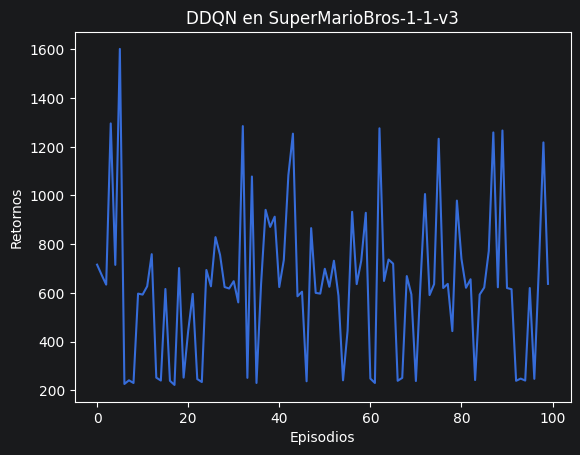

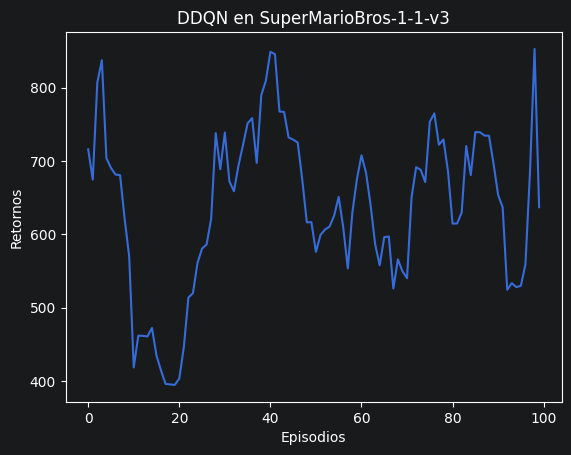

In [17]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DDQN en {}'.format(env_name))
plt.show()

mv_return = moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DDQN en {}'.format(env_name))
plt.show()

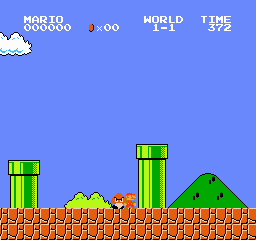

In [19]:
env_name = 'SuperMarioBros-1-1-v0'

env = gym_super_mario_bros.make(env_name, render_mode='rgb_array', apply_api_compatibility=True)
env = JoypadSpace(env, RIGHT_ONLY)
env = apply_wrappers(env)

for _ in range(20):
    state, _ = env.reset()
    episode_return = 0
    for step in range(200):
        state_tensor = torch.tensor(np.array(state), dtype=torch.float32) \
                        .unsqueeze(0) \
                        .to(agent.q_net.device)
        # Escoger la mejor acción de la q_net
        with torch.no_grad():  # No necesitamos calcular gradientes en evaluación
            action = agent.q_net(state_tensor).argmax().item()
        #Obtener s', r', donde e info
        state, reward, done, truncated, info = env.step(action)
        episode_return += reward
    
        img = env.render()

        # Mostrar la imagen con IPython
        clear_output(wait=True)
        display(Image.fromarray(np.array(img), 'RGB'))
        if done:
            break
# Cerrar el ambiente
env.close()